# Cancellation Prediction Model

**Goal:** Predict whether an order will be cancelled, using only information known when the order is placed.

**Models:** Decision Tree (no pruning, pre-pruned, post-pruned), Random Forest, Naive Bayes.

**Note:** Qty, Amount, Status and Courier Status are not used as features, because they directly reveal whether an order was cancelled (data leakage). The data is split 80/20 by Order ID.

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (precision_score, recall_score, f1_score,classification_report, ConfusionMatrixDisplay)

In [20]:
#Load data, features, target, split 
df = pd.read_csv("../data/amazon_cleaned.csv", parse_dates=['Date'])
df['day_of_week'] = df['Date'].dt.day_name()

cat_cols = ['Category', 'Size', 'Fulfilment', 'Sales Channel', 'ship-service-level',
            'fulfilled-by', 'ship-state', 'B2B', 'day_of_week']
X = df[cat_cols].astype(str)
y = df['is_cancelled'].astype(int)

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr, te = next(gss.split(X, y, groups=df['Order ID']))
X_train, X_test, y_train, y_test = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]


In [21]:
# Models 
prep = ColumnTransformer([('ohe', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
models = {
    'Decision Tree (pre-pruned)': DecisionTreeClassifier(max_depth=6, min_samples_leaf=100,
                                                         class_weight='balanced', random_state=42),
    'Decision Tree (post-pruned)': DecisionTreeClassifier(ccp_alpha=0.0005,
                                                          class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=20,
                                            class_weight='balanced', n_jobs=-1, random_state=42),
    'Naive Bayes': BernoulliNB(class_prior=[0.5, 0.5]),
    'Decision Tree (no pruning)': DecisionTreeClassifier(class_weight='balanced', random_state=42),
}

In [28]:
# Train and evaluate
results, fitted = [], {}
for name, m in models.items():
    pipe = Pipeline([('prep', clone(prep)), ('model', m)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results.append({'Model': name,
                    'Accuracy': (pred == y_test).mean(),
                    'Precision': precision_score(y_test, pred, zero_division=0),
                    'Recall': recall_score(y_test, pred),
                    'F1 (train)': f1_score(y_train, pipe.predict(X_train)),
                    'F1 (test)': f1_score(y_test, pred)})
    fitted[name] = pipe

res = pd.DataFrame(results).set_index('Model').round(3)
res.to_csv("../model_results.csv")
display(res)

,Accuracy,Precision,Recall,F1 (train),F1 (test)
Model,,,,,
Decision Tree (pre-pruned),0.613,0.176,0.459,0.251,0.255
Decision Tree (post-pruned),0.635,0.174,0.411,0.244,0.245
Random Forest,0.617,0.177,0.453,0.259,0.254
Naive Bayes,0.655,0.176,0.380,0.236,0.241
Decision Tree (no pruning),0.542,0.155,0.490,0.354,0.236


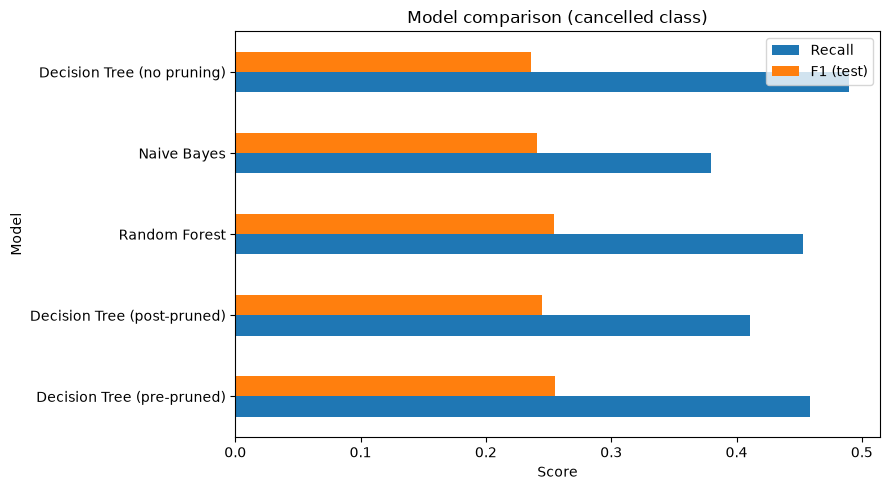

In [23]:
# Comparison chart 
res[['Recall', 'F1 (test)']].plot(kind='barh', figsize=(9, 5))
plt.title('Model comparison (cancelled class)'); plt.xlabel('Score')
plt.tight_layout(); plt.savefig('../images/model_comparison.png', dpi=150); plt.show()

Best model: Decision Tree (pre-pruned)
               precision    recall  f1-score   support

Not cancelled       0.88      0.64      0.74     22037
    Cancelled       0.18      0.46      0.25      3715

     accuracy                           0.61     25752
    macro avg       0.53      0.55      0.50     25752
 weighted avg       0.77      0.61      0.67     25752



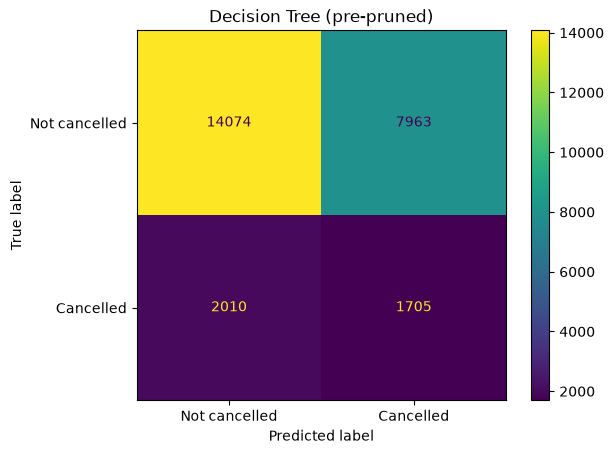

In [24]:
#  Best model: report and confusion matrix 
best_name = res['F1 (test)'].idxmax()
best = fitted[best_name]
print("Best model:", best_name)
print(classification_report(y_test, best.predict(X_test), target_names=['Not cancelled', 'Cancelled']))
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, display_labels=['Not cancelled', 'Cancelled'])
plt.title(best_name)
plt.savefig('../images/confusion_matrix.png', dpi=150, bbox_inches='tight'); plt.show()


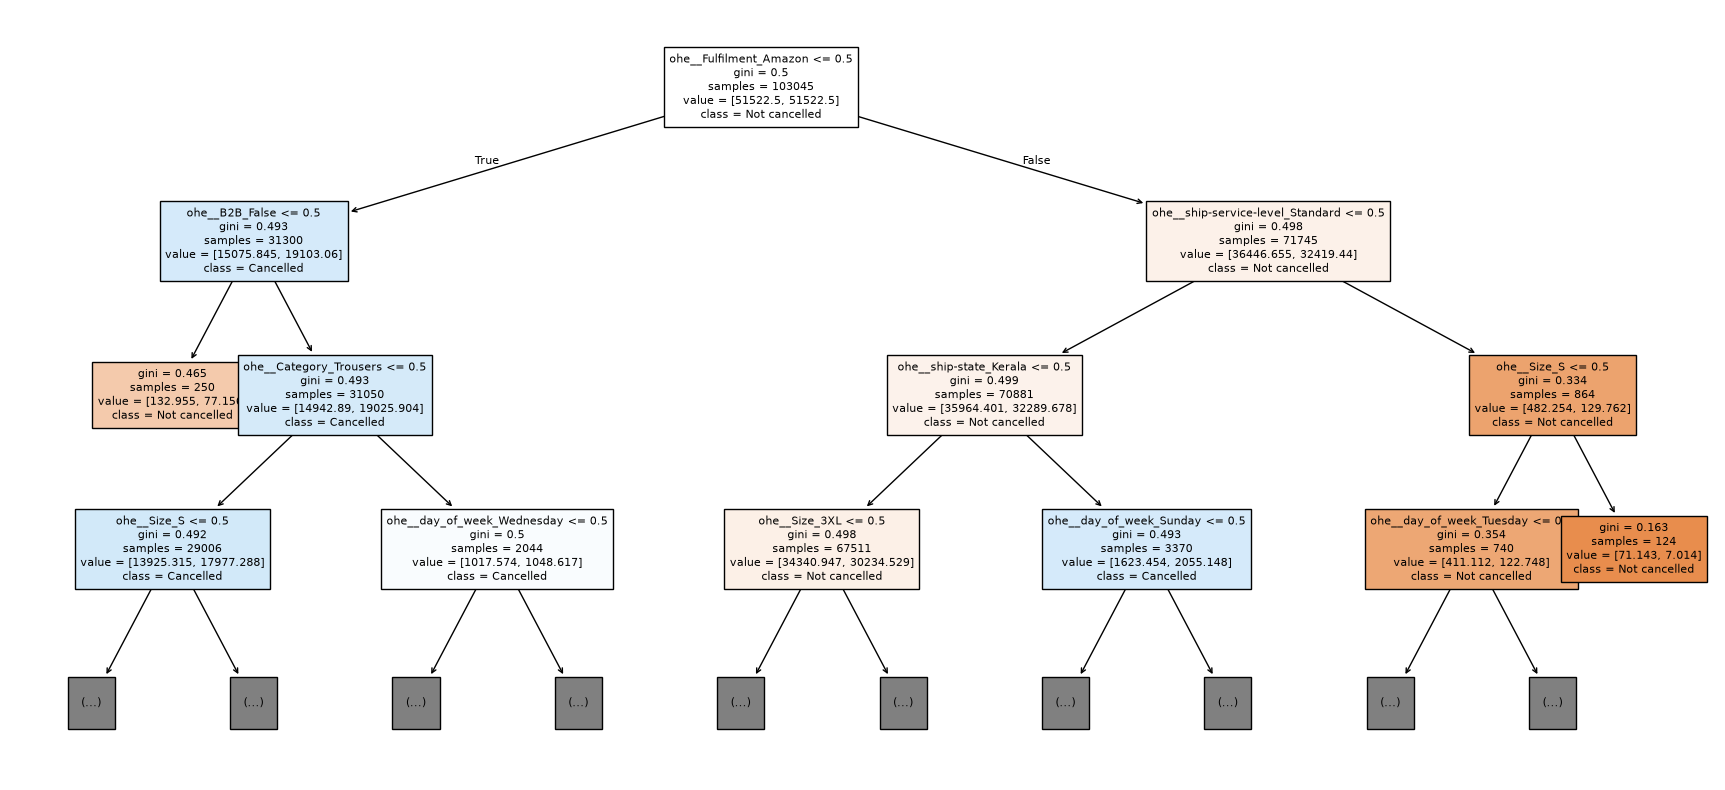

In [25]:
# Decision tree visualization (pre-pruned) 
pre = fitted['Decision Tree (pre-pruned)']
plt.figure(figsize=(22, 10))
plot_tree(pre.named_steps['model'],
          feature_names=pre.named_steps['prep'].get_feature_names_out(),
          class_names=['Not cancelled', 'Cancelled'],
          max_depth=3, filled=True, fontsize=8)
plt.savefig('../images/decision_tree.png', dpi=150, bbox_inches='tight'); plt.show()


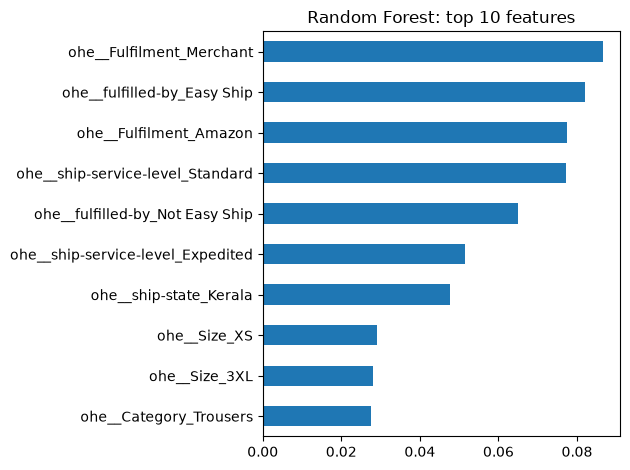

In [26]:
# Random Forest feature importance 
rf = fitted['Random Forest']
names = rf.named_steps['prep'].get_feature_names_out()
imp = pd.Series(rf.named_steps['model'].feature_importances_, index=names).nlargest(10).sort_values()
imp.plot(kind='barh'); plt.title('Random Forest: top 10 features'); plt.tight_layout()
plt.savefig('../images/feature_importance.png', dpi=150); plt.show()


In [27]:
#  10-fold cross-validation (grouped by Order ID) 
cv = GroupKFold(n_splits=10)
cv_rows = []
for name in ['Decision Tree (pre-pruned)', 'Naive Bayes']:
    s = cross_validate(clone(fitted[name]), X, y, groups=df['Order ID'], cv=cv,
                       scoring=['precision', 'recall', 'f1'])
    cv_rows.append({'Model': name, 'Precision': s['test_precision'].mean(),
                    'Recall': s['test_recall'].mean(), 'F1': s['test_f1'].mean(),
                    'F1 std': s['test_f1'].std()})
print(pd.DataFrame(cv_rows).set_index('Model').round(3))

                            Precision  Recall     F1  F1 std
Model                                                       
Decision Tree (pre-pruned)      0.174   0.450  0.251   0.010
Naive Bayes                     0.174   0.373  0.237   0.009


## Limitations

- Only about 3 months of data (31 March to 29 June 2022).
- No customer ID, payment method or stock information, which probably affect cancellations.
- Only order-time features can be used, so the signal is weak.
- Results may not apply to other time periods.
- F1 is about 0.25, so the model is not strong enough for real use.